In [1]:
import os, time, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import pandas as pd

try:
    from IPython.display import display  # nice tables in Jupyter / Colab
except ImportError:
    display = print

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__, "| device:", device)

# Number of epochs (can be reduced for a quick check)
EXP_EPOCHS = int(os.environ.get("EXP_EPOCHS", 10))  # epochs for each tuning experiment
FINAL_EPOCHS = int(os.environ.get("FINAL_EPOCHS", 30))  # epochs for the final (best) model
NUM_WORKERS = 2

PyTorch: 2.15.0+cu132 | torchvision: 0.29.2+cu132 | device: cpu


## Task 1

In [2]:
DATA_PATH = os.environ.get("DATA_PATH", "./data")  # empty directory to download the dataset to
os.makedirs(DATA_PATH, exist_ok=True)

train_raw = torchvision.datasets.CIFAR10(root=DATA_PATH, train=True, download=True)
test_raw = torchvision.datasets.CIFAR10(root=DATA_PATH, train=False, download=True)

classes = train_raw.classes
print("Dataset loaded successfully!")
print("Training images :", len(train_raw))
print("Test images     :", len(test_raw))
print("Raw data array  :", train_raw.data.shape, train_raw.data.dtype)  # (50000, 32, 32, 3) uint8
print("Classes         :", classes)
print("Images per class (train):", np.bincount(train_raw.targets).tolist())
print("Images per class (test) :", np.bincount(test_raw.targets).tolist())

Dataset loaded successfully!
Training images : 50000
Test images     : 10000
Raw data array  : (50000, 32, 32, 3) uint8
Classes         : ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Images per class (train): [5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000]
Images per class (test) : [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]


## Task 2

In [3]:
class SimpleCNN(nn.Module):
    """Baseline: 2 conv + 2 maxpool layers -> fully connected classifier."""

    def __init__(self, num_classes=10):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=5, stride=1, padding=2)  # 3x32x32  -> 32x32x32
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)  # halves H and W
        self.conv2 = nn.Conv2d(32, 64, kernel_size=5, stride=1, padding=2)  # 32x16x16 -> 64x16x16
        self.fc1 = nn.Linear(64 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))  # -> 32 x 16 x 16
        x = self.pool(F.relu(self.conv2(x)))  # -> 64 x 8 x 8
        x = torch.flatten(x, 1)  # -> 4096 features
        x = F.relu(self.fc1(x))
        return self.fc2(x)  # logits (CrossEntropyLoss applies softmax)


class DeepCNN(nn.Module):
    """VGG-style network: 3 blocks of [Conv-BN-ReLU x2 -> MaxPool -> Dropout] + classifier."""

    def __init__(self, num_classes=10, dropout=0.3):
        super().__init__()

        def block(c_in, c_out):
            return nn.Sequential(
                nn.Conv2d(c_in, c_out, kernel_size=3, stride=1, padding=1),
                nn.BatchNorm2d(c_out),
                nn.ReLU(inplace=True),
                nn.Conv2d(c_out, c_out, kernel_size=3, stride=1, padding=1),
                nn.BatchNorm2d(c_out),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(kernel_size=2, stride=2),
                nn.Dropout(dropout),
            )

        self.features = nn.Sequential(
            block(3, 32),  # 3x32x32   -> 32x16x16
            block(32, 64),  # 32x16x16  -> 64x8x8
            block(64, 128),  # 64x8x8    -> 128x4x4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


for name, m in [("SimpleCNN", SimpleCNN()), ("DeepCNN", DeepCNN())]:
    out = m(torch.randn(2, 3, 32, 32))
    print(f"{name}: output shape {tuple(out.shape)}, trainable parameters = {count_params(m):,}")
print(DeepCNN())

SimpleCNN: output shape (2, 10), trainable parameters = 1,105,098
DeepCNN: output shape (2, 10), trainable parameters = 815,018
DeepCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (7): Dropout(p=0.3, inplace=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_siz

In [4]:
def train(model, loader, optimizer, criterion, scheduler=None):
    """Trains the model for ONE epoch. Returns (average train loss, train accuracy %)."""
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad()  # 1. reset gradients
        outputs = model(images)  # 2. forward pass
        loss = criterion(outputs, labels)  # 3. compute loss
        loss.backward()  # 4. backpropagation
        optimizer.step()  # 5. update weights
        if scheduler is not None:  # (per-batch LR schedule, e.g. OneCycleLR)
            scheduler.step()
        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, 100.0 * correct / total


@torch.no_grad()
def test(model, loader, criterion):
    """Evaluates the model on the test set. Returns (average test loss, test accuracy %)."""
    model.eval()  # disables dropout, BN uses running stats
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        outputs = model(images)
        running_loss += criterion(outputs, labels).item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, 100.0 * correct / total

## Task 3

In [5]:
# Dataset wrapper: applies a transform to the raw numpy images (H x W x C uint8)
class CIFARDataset(Dataset):
    def __init__(self, data, targets, transform=None):
        self.data, self.targets, self.transform = data, list(targets), transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img, label = self.data[idx], self.targets[idx]
        if self.transform is not None:
            img = self.transform(img)
        return img, label


# Per-channel mean / std of the CIFAR-10 training set (used by Normalize)
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)

# Basic transform: numpy -> PIL -> tensor (C x H x W, values in [0,1]) -> normalized
basic_transform = T.Compose([T.ToPILImage(), T.ToTensor(), T.Normalize(CIFAR_MEAN, CIFAR_STD)])


def denorm(x):
    """Undo Normalize for display: C x H x W tensor -> H x W x C numpy in [0,1]."""
    mean = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
    std = torch.tensor(CIFAR_STD).view(3, 1, 1)
    return (x * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()


train_set = CIFARDataset(train_raw.data, train_raw.targets, transform=basic_transform)
test_set = CIFARDataset(test_raw.data, test_raw.targets, transform=basic_transform)
train_loader = DataLoader(train_set, batch_size=64, shuffle=True, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_set, batch_size=64, shuffle=False, num_workers=NUM_WORKERS)

images, labels = next(iter(train_loader))  # one batch from the dataloader

# 1. Images tensor size
print("Images tensor size :", images.size())  # [batch, channels, height, width] = [64, 3, 32, 32]
print("Labels tensor size :", labels.size())  # [64]
print("Images dtype       :", images.dtype)
print(
    "Pixel range (after Normalize): min=%.3f, max=%.3f" % (images.min().item(), images.max().item())
)
print("Number of batches  : train =", len(train_loader), "| test =", len(test_loader))

Images tensor size : torch.Size([64, 3, 32, 32])
Labels tensor size : torch.Size([64])
Images dtype       : torch.float32
Pixel range (after Normalize): min=-1.989, max=2.126
Number of batches  : train = 782 | test = 157


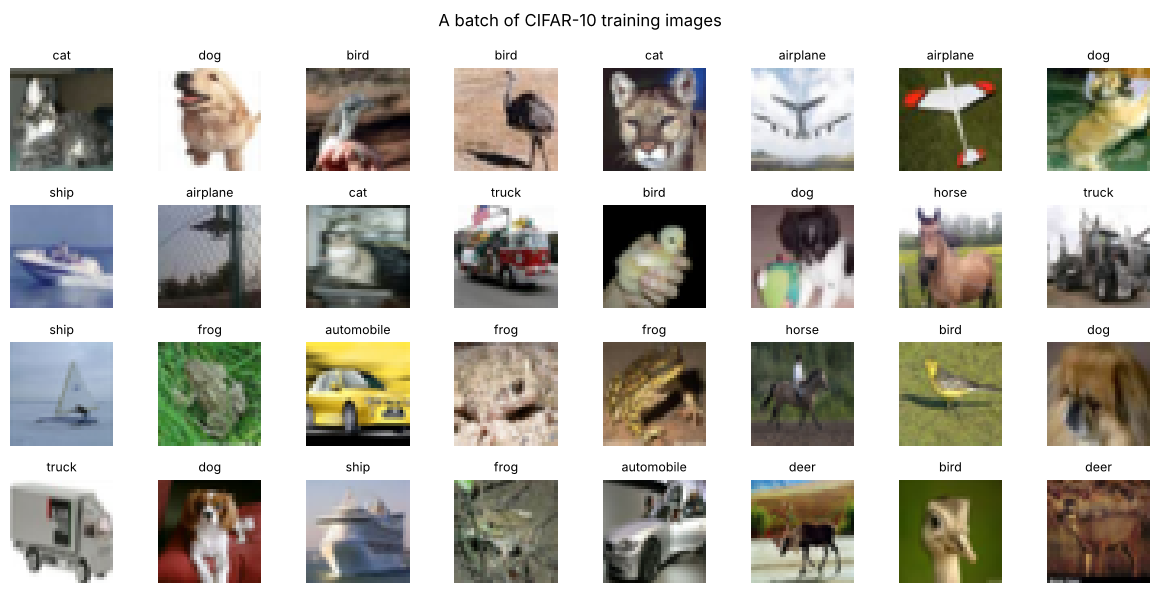

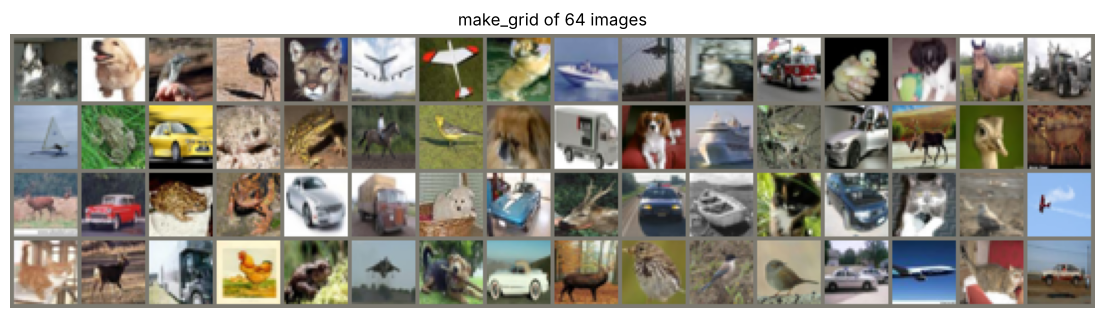

In [6]:
# 2. Data images visualization using matplotlib
fig = plt.figure(figsize=(12, 6))
for i in range(32):
    ax = fig.add_subplot(4, 8, i + 1)
    ax.imshow(denorm(images[i]))
    ax.set_title(classes[labels[i]], fontsize=9)
    ax.axis("off")
plt.suptitle("A batch of CIFAR-10 training images")
plt.tight_layout()
plt.savefig("cifar_batch.png", dpi=120)
plt.show()

# Grid view with torchvision.utils.make_grid
grid = torchvision.utils.make_grid(images[:64], nrow=16)
mean = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
std = torch.tensor(CIFAR_STD).view(3, 1, 1)
plt.figure(figsize=(14, 4))
plt.imshow((grid * std + mean).clamp(0, 1).permute(1, 2, 0).numpy())
plt.axis("off")
plt.title("make_grid of 64 images")
plt.show()

## Task 4

In [7]:
class AddGaussianNoise:
    """Adds Gaussian noise N(mean, std^2) to a tensor image in [0,1]."""

    def __init__(self, mean=0.0, std=0.05, p=0.5):
        self.mean, self.std, self.p = mean, std, p

    def __call__(self, x):
        if random.random() < self.p:
            x = x + torch.randn_like(x) * self.std + self.mean
        return x.clamp(0.0, 1.0)

    def __repr__(self):
        return f"AddGaussianNoise(mean={self.mean}, std={self.std}, p={self.p})"


class AddSaltPepperNoise:
    """Sets a random fraction `amount` of pixels to black (pepper) or white (salt)."""

    def __init__(self, amount=0.02, p=0.5):
        self.amount, self.p = amount, p

    def __call__(self, x):
        if random.random() < self.p:
            mask = torch.rand(1, x.shape[1], x.shape[2])
            x = x.clone()
            x[:, (mask < self.amount / 2)[0]] = 0.0  # pepper
            x[:, (mask > 1 - self.amount / 2)[0]] = 1.0  # salt
        return x

    def __repr__(self):
        return f"AddSaltPepperNoise(amount={self.amount}, p={self.p})"


class AddSpeckleNoise:
    """Multiplicative noise: x + x * N(0, std^2)."""

    def __init__(self, std=0.1, p=0.5):
        self.std, self.p = std, p

    def __call__(self, x):
        if random.random() < self.p:
            x = x + x * torch.randn_like(x) * self.std
        return x.clamp(0.0, 1.0)

    def __repr__(self):
        return f"AddSpeckleNoise(std={self.std}, p={self.p})"


# 1) No augmentation (baseline) - only the mandatory conversions + normalization
no_aug_transform = T.Compose(
    [
        T.ToPILImage(),
        T.ToTensor(),
        T.Normalize(CIFAR_MEAN, CIFAR_STD),
    ]
)

# 2) Standard (light) augmentation
light_aug_transform = T.Compose(
    [
        T.ToPILImage(),  # 1. ToPILImage
        T.RandomHorizontalFlip(p=0.5),  # 2. RandomHorizontalFlip
        T.RandomResizedCrop(32, scale=(0.8, 1.0), ratio=(0.9, 1.1)),  # 3. RandomResizedCrop
        T.ToTensor(),  # 8. ToTensor (C x H x W, [0,1])
        T.Normalize(CIFAR_MEAN, CIFAR_STD),  # 6. Normalize
    ]
)

# 3) Full augmentation - ALL suggested augmentations
full_aug_transform = T.Compose(
    [
        T.ToPILImage(),  # 1. ToPILImage
        T.RandomHorizontalFlip(p=0.5),  # 2. RandomHorizontalFlip
        T.RandomResizedCrop(32, scale=(0.8, 1.0), ratio=(0.9, 1.1)),  # 3. RandomResizedCrop
        T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),  # 4. ColorJitter
        T.RandomRotation(degrees=10),  # 5. RandomRotation
        T.ToTensor(),  # 8. ToTensor
        T.RandomChoice(
            [
                AddGaussianNoise(std=0.03, p=0.5),  # 7. various types of noise
                AddSaltPepperNoise(amount=0.02, p=0.5),
                AddSpeckleNoise(std=0.1, p=0.5),
            ]
        ),
        T.Normalize(CIFAR_MEAN, CIFAR_STD),  # 6. Normalize
    ]
)

# Test transform: NO random augmentation, NO noise, but the SAME normalization
test_transform = T.Compose(
    [
        T.ToPILImage(),
        T.ToTensor(),
        T.Normalize(CIFAR_MEAN, CIFAR_STD),
    ]
)

AUGMENTATIONS = {"none": no_aug_transform, "light": light_aug_transform, "full": full_aug_transform}
print("Full training augmentation pipeline:\n", full_aug_transform)
print("\nTest pipeline:\n", test_transform)


def get_loaders(aug="light", batch_size=128):
    """Train loader uses the chosen augmentation; test loader ALWAYS uses test_transform."""
    train_set = CIFARDataset(train_raw.data, train_raw.targets, transform=AUGMENTATIONS[aug])
    test_set = CIFARDataset(test_raw.data, test_raw.targets, transform=test_transform)
    pin = device.type == "cuda"
    train_loader = DataLoader(
        train_set, batch_size=batch_size, shuffle=True, num_workers=NUM_WORKERS, pin_memory=pin
    )
    test_loader = DataLoader(
        test_set, batch_size=256, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin
    )
    return train_loader, test_loader

Full training augmentation pipeline:
 Compose(
    ToPILImage()
    RandomHorizontalFlip(p=0.5)
    RandomResizedCrop(size=(32, 32), scale=(0.8, 1.0), ratio=(0.9, 1.1), interpolation=bilinear, antialias=True)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=(-0.05, 0.05))
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ToTensor()
    RandomChoice(
    AddGaussianNoise(mean=0.0, std=0.03, p=0.5)
    AddSaltPepperNoise(amount=0.02, p=0.5)
    AddSpeckleNoise(std=0.1, p=0.5)
)(p=None)
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
)

Test pipeline:
 Compose(
    ToPILImage()
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
)


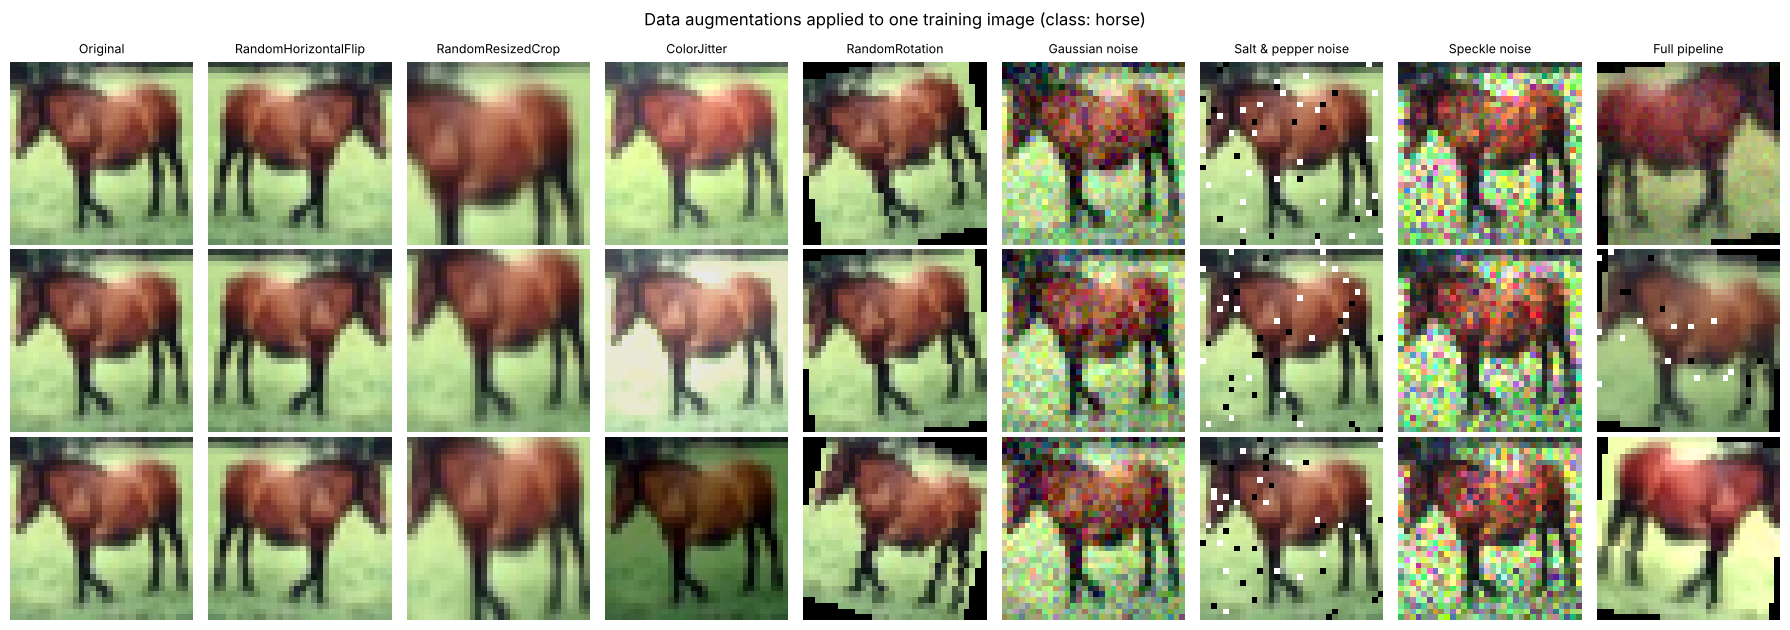

In [8]:
# Visualize every augmentation individually on the same training image

single_augs = {
    "Original": T.Compose([T.ToPILImage(), T.ToTensor()]),
    "RandomHorizontalFlip": T.Compose(
        [T.ToPILImage(), T.RandomHorizontalFlip(p=1.0), T.ToTensor()]
    ),
    "RandomResizedCrop": T.Compose(
        [T.ToPILImage(), T.RandomResizedCrop(32, scale=(0.5, 1.0)), T.ToTensor()]
    ),
    "ColorJitter": T.Compose([T.ToPILImage(), T.ColorJitter(0.5, 0.5, 0.5, 0.1), T.ToTensor()]),
    "RandomRotation": T.Compose([T.ToPILImage(), T.RandomRotation(30), T.ToTensor()]),
    "Gaussian noise": T.Compose([T.ToPILImage(), T.ToTensor(), AddGaussianNoise(std=0.1, p=1.0)]),
    "Salt & pepper noise": T.Compose(
        [T.ToPILImage(), T.ToTensor(), AddSaltPepperNoise(amount=0.05, p=1.0)]
    ),
    "Speckle noise": T.Compose([T.ToPILImage(), T.ToTensor(), AddSpeckleNoise(std=0.3, p=1.0)]),
    "Full pipeline": full_aug_transform,
}
img_np = train_raw.data[7]
fig, axes = plt.subplots(3, len(single_augs), figsize=(2.0 * len(single_augs), 6.4))
for col, (name, tf) in enumerate(single_augs.items()):
    for row in range(3):  # 3 random samples of each augmentation
        out = tf(img_np)
        show = denorm(out) if name == "Full pipeline" else out.permute(1, 2, 0).numpy()
        axes[row, col].imshow(show)
        axes[row, col].axis("off")
    axes[0, col].set_title(name, fontsize=9)
plt.suptitle(
    f"Data augmentations applied to one training image (class: {classes[train_raw.targets[7]]})"
)
plt.tight_layout()
plt.savefig("augmentations.png", dpi=120)
plt.show()

## Task 5

In [9]:
def fit(
    model,
    train_loader,
    test_loader,
    epochs=10,
    optimizer_name="sgd",
    lr=0.01,
    momentum=0.9,
    weight_decay=5e-4,
    schedule="onecycle",
    label_smoothing=0.0,
    verbose=True,
):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    if optimizer_name == "sgd":
        optimizer = optim.SGD(
            model.parameters(), lr=lr, momentum=momentum, weight_decay=weight_decay, nesterov=True
        )
    elif optimizer_name == "adam":
        optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        raise ValueError(optimizer_name)
    scheduler = None
    if schedule == "onecycle":
        scheduler = optim.lr_scheduler.OneCycleLR(
            optimizer, max_lr=lr, epochs=epochs, steps_per_epoch=len(train_loader)
        )
    history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = train(model, train_loader, optimizer, criterion, scheduler)
        te_loss, te_acc = test(model, test_loader, criterion)
        for k, v in zip(history, (tr_loss, tr_acc, te_loss, te_acc)):
            history[k].append(v)
        if verbose:
            print(
                f"Epoch {epoch:2d}/{epochs} | train loss {tr_loss:.4f} | train acc {tr_acc:6.2f}% | "
                f"test loss {te_loss:.4f} | test acc {te_acc:6.2f}% | {time.time() - t0:.1f}s"
            )
    return history


def plot_history(history, title="", fname=None):
    ep = range(1, len(history["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
    ax[0].plot(ep, history["train_loss"], "o-", label="train loss")
    ax[0].set_title("Training loss")
    ax[1].plot(ep, history["test_loss"], "o-", color="tab:orange", label="test loss")
    ax[1].plot(ep, history["train_loss"], "--", color="tab:blue", alpha=0.5, label="train loss")
    ax[1].set_title("Test loss (vs train loss)")
    ax[2].plot(ep, history["test_acc"], "o-", color="tab:green", label="test accuracy")
    ax[2].plot(ep, history["train_acc"], "--", color="tab:red", alpha=0.6, label="train accuracy")
    ax[2].set_title("Test accuracy (%)")
    for a in ax:
        a.set_xlabel("epoch")
        a.grid(alpha=0.3)
        a.legend()
        a.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax[0].set_ylabel("cross-entropy loss")
    ax[2].set_ylabel("accuracy (%)")
    plt.suptitle(title)
    plt.tight_layout()
    if fname:
        plt.savefig(fname, dpi=120)
    plt.show()

In [10]:
EXPERIMENTS = [
    # name                         model        aug      optimizer  lr     batch
    dict(
        name="E1 SimpleCNN, no aug, SGD 0.01, bs64",
        model="simple",
        aug="none",
        opt="sgd",
        lr=0.01,
        bs=64,
        sched="none",
    ),
    dict(
        name="E2 SimpleCNN, light aug, SGD 0.01, bs64",
        model="simple",
        aug="light",
        opt="sgd",
        lr=0.01,
        bs=64,
        sched="none",
    ),
    dict(
        name="E3 DeepCNN, no aug, SGD 0.05, bs128",
        model="deep",
        aug="none",
        opt="sgd",
        lr=0.05,
        bs=128,
        sched="onecycle",
    ),
    dict(
        name="E4 DeepCNN, light aug, SGD 0.05, bs128",
        model="deep",
        aug="light",
        opt="sgd",
        lr=0.05,
        bs=128,
        sched="onecycle",
    ),
    dict(
        name="E5 DeepCNN, full aug, SGD 0.05, bs128",
        model="deep",
        aug="full",
        opt="sgd",
        lr=0.05,
        bs=128,
        sched="onecycle",
    ),
    dict(
        name="E6 DeepCNN, light aug, Adam 1e-3, bs128",
        model="deep",
        aug="light",
        opt="adam",
        lr=1e-3,
        bs=128,
        sched="onecycle",
    ),
    dict(
        name="E7 DeepCNN, light aug, SGD 0.2, bs256",
        model="deep",
        aug="light",
        opt="sgd",
        lr=0.2,
        bs=256,
        sched="onecycle",
    ),
]

results = {}
for cfg in EXPERIMENTS:
    print("\n" + "=" * 100 + "\n" + cfg["name"] + "\n" + "=" * 100)
    torch.manual_seed(SEED)
    tr_loader, te_loader = get_loaders(aug=cfg["aug"], batch_size=cfg["bs"])
    model = SimpleCNN() if cfg["model"] == "simple" else DeepCNN()
    wd = 5e-4 if cfg["opt"] == "sgd" else 1e-4
    t0 = time.time()
    hist = fit(
        model,
        tr_loader,
        te_loader,
        epochs=EXP_EPOCHS,
        optimizer_name=cfg["opt"],
        lr=cfg["lr"],
        weight_decay=wd,
        schedule=cfg["sched"],
    )
    hist["time_min"] = (time.time() - t0) / 60
    results[cfg["name"]] = hist


E1 SimpleCNN, no aug, SGD 0.01, bs64


Epoch  1/10 | train loss 1.3532 | train acc  51.79% | test loss 1.0982 | test acc  60.71% | 33.2s


Epoch  2/10 | train loss 0.9178 | train acc  67.77% | test loss 0.9300 | test acc  67.47% | 31.3s


Epoch  3/10 | train loss 0.7325 | train acc  74.51% | test loss 0.8716 | test acc  70.53% | 30.4s


Epoch  4/10 | train loss 0.5862 | train acc  79.42% | test loss 0.8176 | test acc  72.93% | 33.9s


Epoch  5/10 | train loss 0.4607 | train acc  83.63% | test loss 0.8841 | test acc  72.12% | 30.8s


... (61 outputs left out)

Epoch  7/10 | train loss 0.7406 | train acc  74.79% | test loss 0.6426 | test acc  78.42% | 82.9s


Epoch  8/10 | train loss 0.6817 | train acc  76.51% | test loss 0.6618 | test acc  77.22% | 81.0s


Epoch  9/10 | train loss 0.6134 | train acc  79.04% | test loss 0.5293 | test acc  81.94% | 76.7s


Epoch 10/10 | train loss 0.5622 | train acc  80.68% | test loss 0.5307 | test acc  81.79% | 78.8s


,experiment,train_loss,test_loss,train_acc,test_acc,best_test_acc,time_min
2,"E3 DeepCNN, no aug, SGD 0.05, bs128",0.4448,0.4566,84.776,84.61,84.61,12.6251
6,"E7 DeepCNN, light aug, SGD 0.2, bs256",0.5622,0.5307,80.680,81.79,81.94,13.8896
3,"E4 DeepCNN, light aug, SGD 0.05, bs128",0.5792,0.5568,80.222,80.86,80.86,12.9651
5,"E6 DeepCNN, light aug, Adam 1e-3, bs128",0.6158,0.6000,78.862,79.50,79.50,13.8277
4,"E5 DeepCNN, full aug, SGD 0.05, bs128",0.7632,0.6084,73.554,79.24,79.24,16.7504
1,"E2 SimpleCNN, light aug, SGD 0.01, bs64",0.5193,0.7318,81.784,77.20,77.20,6.2596
0,"E1 SimpleCNN, no aug, SGD 0.01, bs64",0.1185,1.1751,95.914,74.22,74.22,5.4169


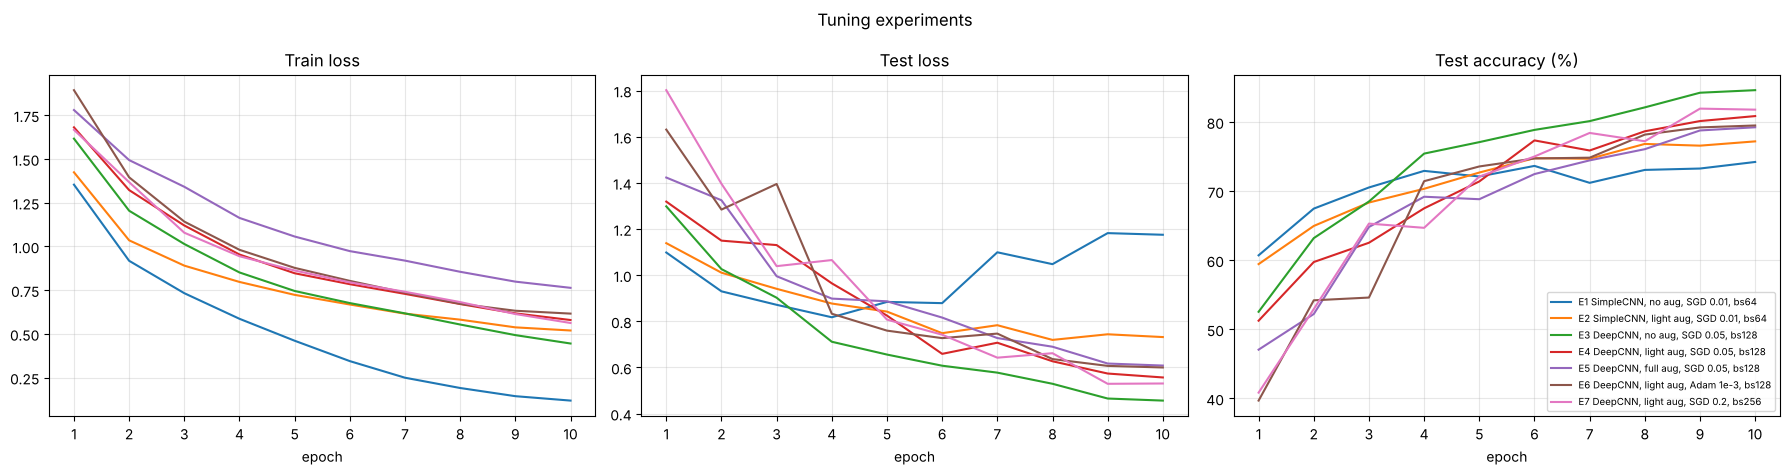

Best experiment (final test accuracy): E3 DeepCNN, no aug, SGD 0.05, bs128


In [11]:
# Comparison table + comparison plots
exp_table = pd.DataFrame(
    [
        {
            "experiment": n,
            "train_loss": h["train_loss"][-1],
            "test_loss": h["test_loss"][-1],
            "train_acc": h["train_acc"][-1],
            "test_acc": h["test_acc"][-1],
            "best_test_acc": max(h["test_acc"]),
            "time_min": h["time_min"],
        }
        for n, h in results.items()
    ]
).sort_values("test_acc", ascending=False)
display(exp_table.round(4))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
for name, h in results.items():
    ep = range(1, len(h["train_loss"]) + 1)
    ax[0].plot(ep, h["train_loss"], label=name)
    ax[1].plot(ep, h["test_loss"], label=name)
    ax[2].plot(ep, h["test_acc"], label=name)
for a, t in zip(ax, ["Train loss", "Test loss", "Test accuracy (%)"]):
    a.set_title(t)
    a.set_xlabel("epoch")
    a.grid(alpha=0.3)
    a.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax[2].legend(fontsize=7, loc="lower right")
plt.suptitle("Tuning experiments")
plt.tight_layout()
plt.savefig("experiments_comparison.png", dpi=120)
plt.show()

best_exp = max(results, key=lambda n: results[n]["test_acc"][-1])
print("Best experiment (final test accuracy):", best_exp)

Final training with configuration: {'name': 'E3 DeepCNN, no aug, SGD 0.05, bs128', 'model': 'deep', 'aug': 'none', 'opt': 'sgd', 'lr': 0.05, 'bs': 128, 'sched': 'onecycle'} | epochs: 30


Epoch  1/30 | train loss 1.6426 | train acc  38.73% | test loss 1.3491 | test acc  50.68% | 66.3s


Epoch  2/30 | train loss 1.2075 | train acc  56.24% | test loss 1.0812 | test acc  61.43% | 255.9s


Epoch  3/30 | train loss 1.0351 | train acc  63.51% | test loss 0.8555 | test acc  69.67% | 109.0s


Epoch  4/30 | train loss 0.9315 | train acc  67.56% | test loss 0.8601 | test acc  70.47% | 67.2s


Epoch  5/30 | train loss 0.8519 | train acc  70.42% | test loss 0.8179 | test acc  71.79% | 66.0s


... (21 outputs left out)

Epoch 27/30 | train loss 0.2458 | train acc  91.56% | test loss 0.3897 | test acc  87.45% | 67.9s


Epoch 28/30 | train loss 0.2304 | train acc  91.97% | test loss 0.3865 | test acc  87.75% | 72.9s


Epoch 29/30 | train loss 0.2107 | train acc  92.64% | test loss 0.3845 | test acc  87.86% | 73.4s


Epoch 30/30 | train loss 0.2039 | train acc  92.87% | test loss 0.3800 | test acc  87.92% | 77.2s

================ FINAL RESULTS ================
Final train loss    : 0.2039
Final train accuracy: 92.87%
Final test loss     : 0.3800
Final test accuracy : 87.92%


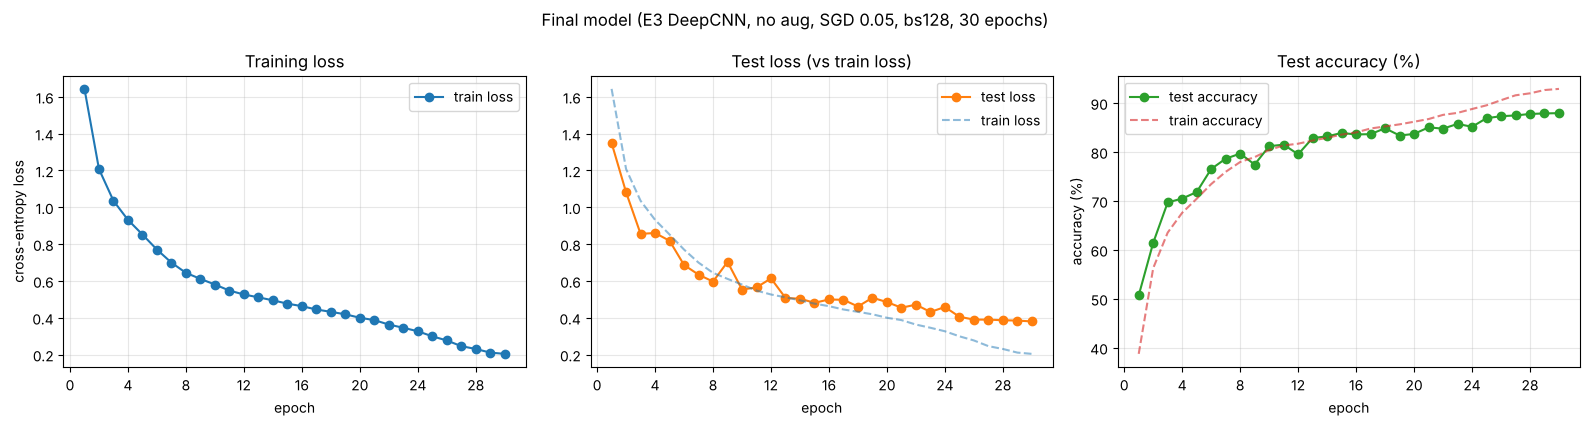

,train_loss,train_acc,test_loss,test_acc
1,1.6426,38.732,1.3491,50.68
2,1.2075,56.244,1.0812,61.43
3,1.0351,63.512,0.8555,69.67
4,0.9315,67.560,0.8601,70.47
5,0.8519,70.424,0.8179,71.79
6,0.7701,73.422,0.6864,76.51
7,0.6992,75.924,0.6339,78.61
8,0.6438,77.934,0.5963,79.65
9,0.6110,78.930,0.7033,77.42
10,0.5803,80.398,0.5532,81.16


In [12]:
best_cfg = next(c for c in EXPERIMENTS if c["name"] == best_exp)
print("Final training with configuration:", best_cfg, "| epochs:", FINAL_EPOCHS)
torch.manual_seed(SEED)
tr_loader, te_loader = get_loaders(aug=best_cfg["aug"], batch_size=best_cfg["bs"])
final_model = SimpleCNN() if best_cfg["model"] == "simple" else DeepCNN()
final_hist = fit(
    final_model,
    tr_loader,
    te_loader,
    epochs=FINAL_EPOCHS,
    optimizer_name=best_cfg["opt"],
    lr=best_cfg["lr"],
    weight_decay=5e-4 if best_cfg["opt"] == "sgd" else 1e-4,
    schedule=best_cfg["sched"],
)

print("\n================ FINAL RESULTS ================")
print(f"Final train loss    : {final_hist['train_loss'][-1]:.4f}")
print(f"Final train accuracy: {final_hist['train_acc'][-1]:.2f}%")
print(f"Final test loss     : {final_hist['test_loss'][-1]:.4f}")
print(f"Final test accuracy : {final_hist['test_acc'][-1]:.2f}%")
plot_history(
    final_hist,
    title=f"Final model ({best_cfg['name']}, {FINAL_EPOCHS} epochs)",
    fname="final_curves.png",
)
display(
    pd.DataFrame(
        {k: final_hist[k] for k in ["train_loss", "train_acc", "test_loss", "test_acc"]},
        index=range(1, FINAL_EPOCHS + 1),
    ).round(4)
)

Candidate 2 (best experiment with augmentation): E7 DeepCNN, light aug, SGD 0.2, bs256 | epochs: 30


Epoch  1/30 | train loss 1.6480 | train acc  38.33% | test loss 1.3200 | test acc  51.37% | 98.8s


Epoch  2/30 | train loss 1.2639 | train acc  54.46% | test loss 1.1887 | test acc  58.92% | 95.2s


Epoch  3/30 | train loss 1.1329 | train acc  60.36% | test loss 1.1675 | test acc  62.30% | 88.1s


Epoch  4/30 | train loss 1.0176 | train acc  64.94% | test loss 0.9459 | test acc  67.46% | 85.7s


Epoch  5/30 | train loss 0.8927 | train acc  69.20% | test loss 0.9356 | test acc  68.82% | 86.4s


... (21 outputs left out)

Epoch 27/30 | train loss 0.4219 | train acc  85.53% | test loss 0.3989 | test acc  86.61% | 86.7s


Epoch 28/30 | train loss 0.3955 | train acc  86.45% | test loss 0.4150 | test acc  86.06% | 90.0s


Epoch 29/30 | train loss 0.3751 | train acc  87.19% | test loss 0.3992 | test acc  86.55% | 89.9s


Epoch 30/30 | train loss 0.3658 | train acc  87.32% | test loss 0.3882 | test acc  86.97% | 86.7s


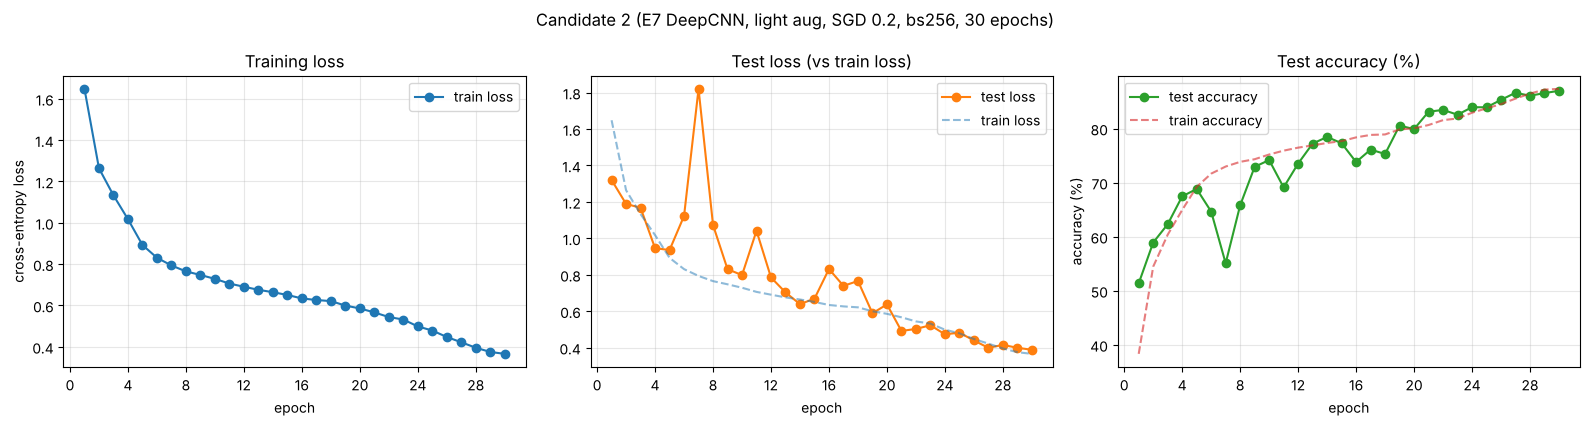

In [13]:
cand_A_cfg, cand_A_model, cand_A_hist = best_cfg, final_model, final_hist
aug_exps = [c for c in EXPERIMENTS if c["aug"] != "none"]
cand_B_cfg = max(aug_exps, key=lambda c: results[c["name"]]["test_acc"][-1])
print(
    "Candidate 2 (best experiment with augmentation):",
    cand_B_cfg["name"],
    "| epochs:",
    FINAL_EPOCHS,
)
if cand_B_cfg["name"] != cand_A_cfg["name"]:
    torch.manual_seed(SEED)
    tr_loader_B, te_loader_B = get_loaders(aug=cand_B_cfg["aug"], batch_size=cand_B_cfg["bs"])
    cand_B_model = SimpleCNN() if cand_B_cfg["model"] == "simple" else DeepCNN()
    cand_B_hist = fit(
        cand_B_model,
        tr_loader_B,
        te_loader_B,
        epochs=FINAL_EPOCHS,
        optimizer_name=cand_B_cfg["opt"],
        lr=cand_B_cfg["lr"],
        weight_decay=5e-4 if cand_B_cfg["opt"] == "sgd" else 1e-4,
        schedule=cand_B_cfg["sched"],
    )
    plot_history(
        cand_B_hist,
        title=f"Candidate 2 ({cand_B_cfg['name']}, {FINAL_EPOCHS} epochs)",
        fname="final_curves_aug.png",
    )
else:
    cand_B_model, cand_B_hist = cand_A_model, cand_A_hist

,candidate,train_loss,test_loss,train_acc,test_acc,gap (train_acc - test_acc)
0,"E3 DeepCNN, no aug, SGD 0.05, bs128",0.2039,0.3800,92.874,87.92,4.954
1,"E7 DeepCNN, light aug, SGD 0.2, bs256",0.3658,0.3882,87.324,86.97,0.354


FINAL MODEL (highest test accuracy): E3 DeepCNN, no aug, SGD 0.05, bs128


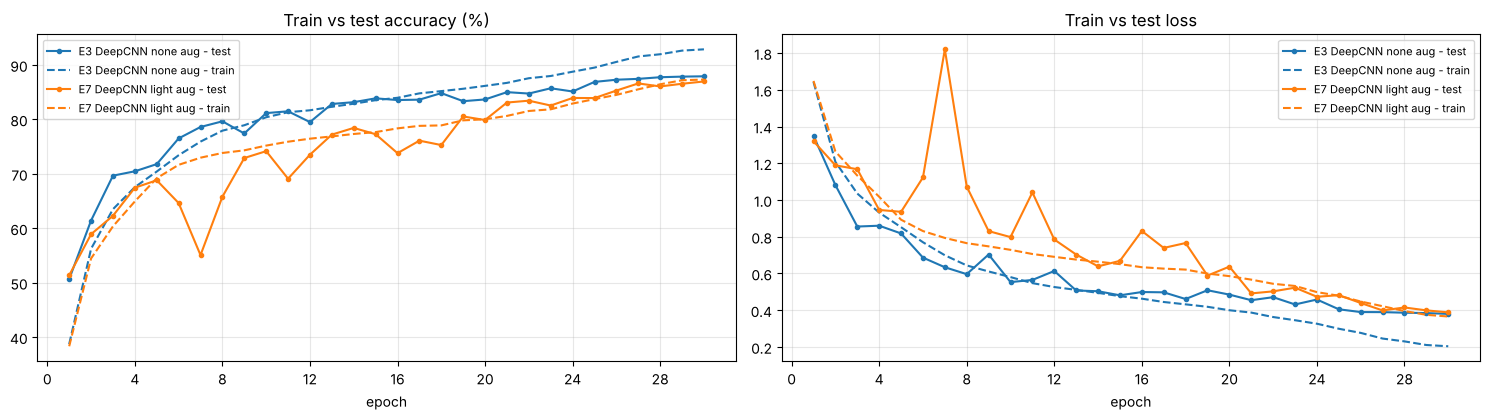

In [14]:
candidates = {
    cand_A_cfg["name"]: (cand_A_cfg, cand_A_model, cand_A_hist),
    cand_B_cfg["name"]: (cand_B_cfg, cand_B_model, cand_B_hist),
}
cmp_table = pd.DataFrame(
    [
        {
            "candidate": n,
            "train_loss": h["train_loss"][-1],
            "test_loss": h["test_loss"][-1],
            "train_acc": h["train_acc"][-1],
            "test_acc": h["test_acc"][-1],
            "gap (train_acc - test_acc)": h["train_acc"][-1] - h["test_acc"][-1],
        }
        for n, (c, m, h) in candidates.items()
    ]
)
display(cmp_table.round(4))

final_name = max(candidates, key=lambda n: candidates[n][2]["test_acc"][-1])
best_cfg, final_model, final_hist = candidates[final_name]
te_loader = get_loaders(aug="none", batch_size=256)[1]  # clean test loader (no augmentation)
print("FINAL MODEL (highest test accuracy):", final_name)

# train vs test accuracy of both candidates on the same plot
fig, ax = plt.subplots(1, 2, figsize=(15, 4.3))
for n, (c, m, h) in candidates.items():
    ep = range(1, len(h["train_acc"]) + 1)
    (l,) = ax[0].plot(
        ep, h["test_acc"], "o-", ms=3, label=f"{n.split(',')[0]} {c['aug']} aug - test"
    )
    ax[0].plot(
        ep,
        h["train_acc"],
        "--",
        color=l.get_color(),
        label=f"{n.split(',')[0]} {c['aug']} aug - train",
    )
    ax[1].plot(
        ep,
        h["test_loss"],
        "o-",
        ms=3,
        color=l.get_color(),
        label=f"{n.split(',')[0]} {c['aug']} aug - test",
    )
    ax[1].plot(
        ep,
        h["train_loss"],
        "--",
        color=l.get_color(),
        label=f"{n.split(',')[0]} {c['aug']} aug - train",
    )
ax[0].set_title("Train vs test accuracy (%)")
ax[1].set_title("Train vs test loss")
for a in ax:
    a.set_xlabel("epoch")
    a.grid(alpha=0.3)
    a.legend(fontsize=8)
    a.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.tight_layout()
plt.savefig("overfitting_comparison.png", dpi=120)
plt.show()

In [15]:
# Per-class test accuracy of the final model
@torch.no_grad()
def per_class_accuracy(model, loader):
    model.eval()
    correct = torch.zeros(10)
    total = torch.zeros(10)
    for x, y in loader:
        pred = model(x.to(device)).argmax(1).cpu()
        for c in range(10):
            m = y == c
            correct[c] += (pred[m] == c).sum()
            total[c] += m.sum()
    return 100 * correct / total


for c, acc in zip(classes, per_class_accuracy(final_model, te_loader)):
    print(f"{c:12s}: {acc:.2f}%")

airplane    : 89.00%
automobile  : 93.90%
bird        : 79.90%
cat         : 71.00%
deer        : 89.50%
dog         : 84.20%
frog        : 93.00%
horse       : 91.20%
ship        : 94.10%
truck       : 93.40%


Correct: 16 out of 16


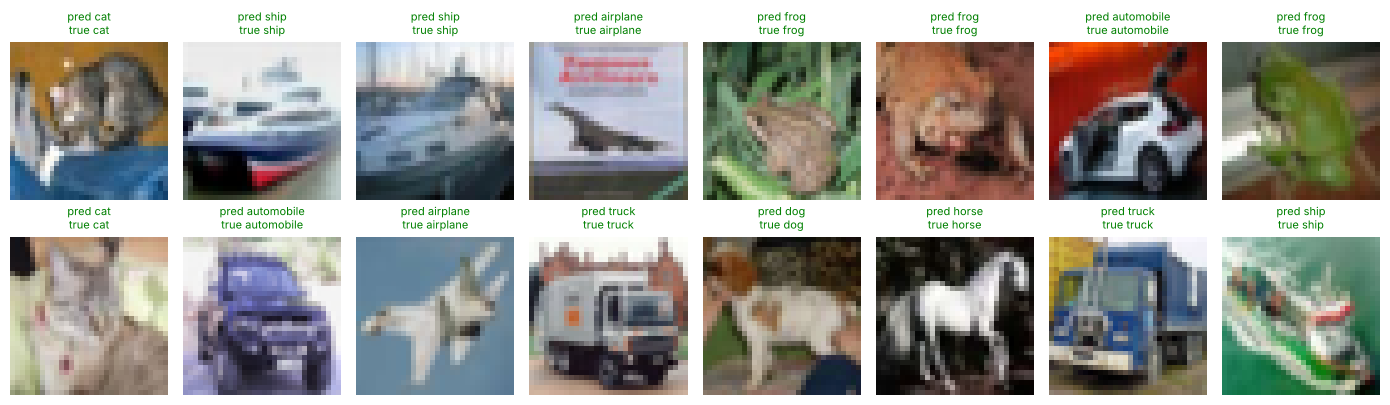

In [16]:
# Testing the final network on a few test images (green = correct, red = wrong)
final_model.eval()
test_images, test_labels = next(iter(te_loader))
with torch.no_grad():
    preds = final_model(test_images.to(device)).argmax(1).cpu()
print("Correct:", (preds[:16] == test_labels[:16]).sum().item(), "out of 16")
fig, axes = plt.subplots(2, 8, figsize=(14, 4.2))
for ax, img, label, pred in zip(axes.flat, test_images, test_labels, preds):
    ax.imshow(denorm(img))
    ax.axis("off")
    ax.set_title(
        f"pred {classes[pred]}\ntrue {classes[label]}",
        fontsize=8,
        color="green" if pred == label else "red",
    )
plt.tight_layout()
plt.savefig("test_predictions.png", dpi=120)
plt.show()

In [17]:
# Summary of the results
print("Best design:", best_cfg["name"])
print(
    f"  network       : {'DeepCNN (6 conv layers + BatchNorm + 3 MaxPool + Dropout)' if best_cfg['model']=='deep' else 'SimpleCNN (2 conv + 2 MaxPool)'}"
)
print(
    f"  optimizer     : {best_cfg['opt'].upper()}, max learning rate {best_cfg['lr']}, schedule {best_cfg['sched']}"
)
print(f"  batch size    : {best_cfg['bs']}")
print(f"  augmentation  : {best_cfg['aug']}")
print(f"  epochs        : {FINAL_EPOCHS}")
print(
    f"Final train loss = {final_hist['train_loss'][-1]:.4f} | Final test loss = {final_hist['test_loss'][-1]:.4f} | "
    f"Final test accuracy = {final_hist['test_acc'][-1]:.2f}% (best epoch: {max(final_hist['test_acc']):.2f}%)"
)

Best design: E3 DeepCNN, no aug, SGD 0.05, bs128
  network       : DeepCNN (6 conv layers + BatchNorm + 3 MaxPool + Dropout)
  optimizer     : SGD, max learning rate 0.05, schedule onecycle
  batch size    : 128
  augmentation  : none
  epochs        : 30
Final train loss = 0.2039 | Final test loss = 0.3800 | Final test accuracy = 87.92% (best epoch: 87.92%)


## Task 6

In [18]:
torch.save(final_model.state_dict(), "cifar10_cnn_final.pth")
import json

with open("results.json", "w") as f:
    json.dump(
        {
            "experiments": results,
            "final": final_hist,
            "best_config": best_cfg,
            "candidates": {n: {"config": c, "history": h} for n, (c, m, h) in candidates.items()},
        },
        f,
        indent=2,
    )
print("Saved: cifar10_cnn_final.pth, results.json, and all figures (*.png)")

Saved: cifar10_cnn_final.pth, results.json, and all figures (*.png)
